# Web-Google Dataset Exploration

This notebook prepares the project imports and loads the SNAP Web-Google graph for exploration. The graph loader checks and reuses the processed cache when it is valid.

## Project setup

Resolve the repository root relative to the notebook working directory, then add it to Python's import path so project modules can be imported reliably.

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebooks"
    else Path.cwd()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.graph_processor import load_graph_data

DATASET_PATH = PROJECT_ROOT / "data" / "web-Google.txt"

## Load the graph

`load_graph_data()` reads the dataset and reuses the validated files in `data/processed/` when available. It returns the sparse adjacency matrix, original node IDs and mapping, degree arrays, and PageRank scores in the same node order.

In [5]:
graph_data = load_graph_data(DATASET_PATH)

adjacency = graph_data["adjacency"]
node_ids = graph_data["node_ids"]
node_to_index = graph_data["node_to_index"]
in_degree = graph_data["in_degree"]
out_degree = graph_data["out_degree"]
pagerank = graph_data["pagerank"]

print(f"Dataset shape (nodes, edges): ({len(node_ids)}, {adjacency.nnz})")
print(f"Number of nodes: {len(node_ids):,}")
print(f"Number of directed edges: {adjacency.nnz:,}")
print(f"Adjacency format: {adjacency.format}")
print(f"PageRank score sum: {np.sum(pagerank):.12f}")

Dataset shape (nodes, edges): (875713, 5105039)
Number of nodes: 875,713
Number of directed edges: 5,105,039
Adjacency format: csr
PageRank score sum: 1.000000000000


## Degree Distribution Analysis

The degree arrays loaded above describe the number of incoming and outgoing links for each original graph node. The following summaries and plots analyze those arrays without reloading the dataset or recalculating PageRank.

### Degree summary

Compare average, median, and maximum degrees, and count nodes with no incoming or outgoing links. These calculations operate directly on the existing degree arrays.

In [6]:
print(f"Nodes analyzed: {len(node_ids):,}")
print(f"Average in-degree:  {np.mean(in_degree):.2f}")
print(f"Average out-degree: {np.mean(out_degree):.2f}")
print(f"Median in-degree:   {np.median(in_degree):.2f}")
print(f"Median out-degree:  {np.median(out_degree):.2f}")
print(f"Maximum in-degree:  {np.max(in_degree):,}")
print(f"Maximum out-degree: {np.max(out_degree):,}")
print(f"Zero in-degree nodes:  {np.count_nonzero(in_degree == 0):,}")
print(f"Zero out-degree nodes: {np.count_nonzero(out_degree == 0):,}")

Nodes analyzed: 875,713
Average in-degree:  5.83
Average out-degree: 5.83
Median in-degree:   1.00
Median out-degree:  4.00
Maximum in-degree:  6,326
Maximum out-degree: 456
Zero in-degree nodes:  161,168
Zero out-degree nodes: 136,259


### In-degree and out-degree histograms

The two histograms show the full distributions. Their y-axes use a logarithmic scale so that both frequent low-degree values and the less common high-degree nodes remain visible.

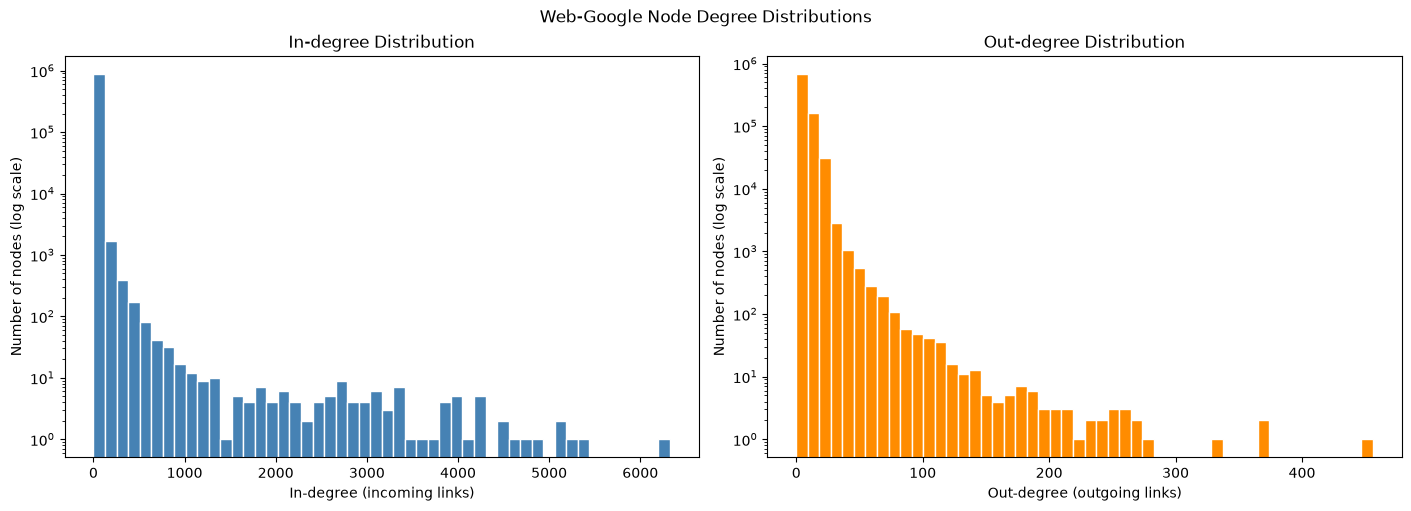

In [9]:
FIGURE_DIR = PROJECT_ROOT / Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

axes[0].hist(in_degree, bins=50, color="steelblue", edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_title("In-degree Distribution")
axes[0].set_xlabel("In-degree (incoming links)")
axes[0].set_ylabel("Number of nodes (log scale)")

axes[1].hist(out_degree, bins=50, color="darkorange", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("Out-degree Distribution")
axes[1].set_xlabel("Out-degree (outgoing links)")
axes[1].set_ylabel("Number of nodes (log scale)")

fig.suptitle("Web-Google Node Degree Distributions")
fig.savefig(FIGURE_DIR / "degree_histograms.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### Log-log degree frequency

This plot compares how many nodes have each positive degree. Zero-degree nodes are excluded because zero cannot be displayed on logarithmic axes; frequencies are counted from the observed degree values.

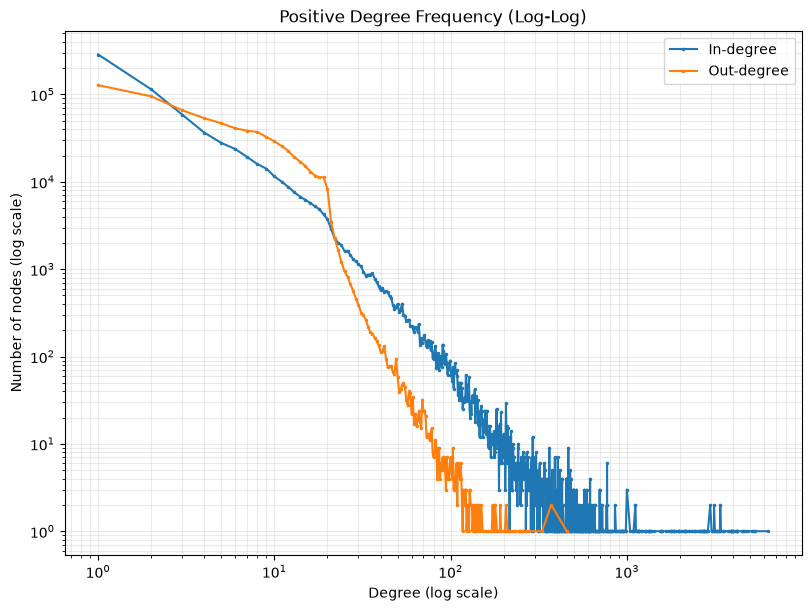

In [10]:
in_degree_values, in_degree_frequency = np.unique(in_degree, return_counts=True)
out_degree_values, out_degree_frequency = np.unique(out_degree, return_counts=True)
positive_in_degree = in_degree_values > 0
positive_out_degree = out_degree_values > 0

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.loglog(
    in_degree_values[positive_in_degree],
    in_degree_frequency[positive_in_degree],
    ".-",
    markersize=3,
    label="In-degree",
)
ax.loglog(
    out_degree_values[positive_out_degree],
    out_degree_frequency[positive_out_degree],
    ".-",
    markersize=3,
    label="Out-degree",
)
ax.set_title("Positive Degree Frequency (Log-Log)")
ax.set_xlabel("Degree (log scale)")
ax.set_ylabel("Number of nodes (log scale)")
ax.legend()
ax.grid(True, which="both", alpha=0.25)
fig.savefig(FIGURE_DIR / "degree_frequency_loglog.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)